# Fase 3 — Detecção de Anomalias

### Saídas
- `data/processed/results_summary.csv` — métricas por modelo e configuração
- `data/processed/anomalies_combined.parquet` — dataset com flags e scores dos dois modelos
- `data/processed/anomalies_high_confidence.parquet` — registros detectados por ambos os modelos

---
**Pré-requisito:** executar `fase2_feature_engineering.ipynb` antes deste notebook.

## 0. Dependências

In [1]:
import re
import warnings
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    confusion_matrix, precision_recall_curve, auc
)

warnings.filterwarnings('ignore')

import sklearn
print(f'scikit-learn : {sklearn.__version__}')
print(f'pandas       : {pd.__version__}')
print(f'numpy        : {np.__version__}')

scikit-learn : 1.8.0
pandas       : 3.0.3
numpy        : 2.4.5


## 1. Carregamento dos Dados

In [2]:
# ── Caminhos ──────────────────────────────────────────────────────────────────
PROCESSED_DIR = Path('../data/processed')   # ajuste se necessário
FEATURES_FILE = PROCESSED_DIR / 'features.parquet'
FULL_FILE     = PROCESSED_DIR / 'logs_with_features.parquet'
# ──────────────────────────────────────────────────────────────────────────────

for f in [FEATURES_FILE, FULL_FILE]:
    if not f.exists():
        raise FileNotFoundError(
            f'Arquivo não encontrado: {f}\n'
            f'Execute fase2_feature_engineering.ipynb primeiro.'
        )

features_raw = pd.read_parquet(FEATURES_FILE)
logs         = pd.read_parquet(FULL_FILE)

print(f'Features carregadas : {features_raw.shape[0]:,} linhas × {features_raw.shape[1]} features')
print(f'Dataset completo    : {logs.shape[0]:,} linhas × {logs.shape[1]} colunas')
print(f'Período             : {logs["timestamp"].min()} → {logs["timestamp"].max()}')

Features carregadas : 2,353,220 linhas × 37 features
Dataset completo    : 2,353,220 linhas × 50 colunas
Período             : 2023-06-06 06:31:05+00:00 → 2023-06-21 06:31:16+00:00


## 2. Seleção de Features e Escalonamento

### 2.1 — Remoção de Features Redundantes

A análise de correlação de Spearman da Fase 2 identificou pares com r > 0.95. Features altamente correlacionadas não adicionam informação — apenas ruído e custo computacional.

In [3]:
REDUNDANT_FEATURES = [
    'uri_query_length',        # r=0.998 com uri_param_count
    'hour_of_day',             # substituído por hour_sin/hour_cos (encoding cíclico)
    'time_period',             # redundante com hour_sin/hour_cos
    'day_of_week',             # substituído por dow_sin/dow_cos
    'ip_distinct_uris_prev1h', # r=0.990 com ip_req_count; ip_uri_diversity já captura a relação
    'ip_bytes_total_prev1h',   # r=0.960 com ip_req_count
    'ip_bytes_mean_prev1h',    # r=0.955 com ip_bytes_total
    'status_code',             # r=0.998 com status_family
    'is_success',              # r=-0.997 com status_family
    'is_not_found',            # r=0.986 com is_client_error
    'version_is_http11',       # r=-1.0 com version_is_http10
]

to_remove = [f for f in REDUNDANT_FEATURES if f in features_raw.columns]
features  = features_raw.drop(columns=to_remove)

print(f'Features removidas por redundância : {len(to_remove)}')
print(f'Features restantes                 : {len(features.columns)}')
print()
print('Conjunto final:')
for i, col in enumerate(features.columns, 1):
    print(f'  {i:2d}. {col}')

Features removidas por redundância : 0
Features restantes                 : 37

Conjunto final:
   1. uri_length
   2. uri_depth
   3. uri_param_count
   4. uri_has_susp_ext
   5. uri_has_attack_pattern
   6. uri_encoded_chars
   7. uri_double_encoded
   8. uri_is_root
   9. is_weekend
  10. is_business_hours
  11. hour_sin
  12. hour_cos
  13. dow_sin
  14. dow_cos
  15. ip_req_count_prev1h
  16. ip_distinct_hosts_prev1h
  17. ip_error_rate_prev1h
  18. ip_post_rate_prev1h
  19. ip_uri_diversity_prev1h
  20. ua_is_missing
  21. ua_length
  22. ua_is_known_bot
  23. ua_is_scanner
  24. ua_is_browser
  25. ua_is_unknown_type
  26. status_family
  27. is_redirect
  28. is_client_error
  29. is_server_error
  30. is_forbidden
  31. is_timeout
  32. bytes_is_zero
  33. bytes_log
  34. method_is_get
  35. method_is_post
  36. method_is_unusual
  37. version_is_http10


### 2.2 — Escalonamento com RobustScaler

As features têm escalas muito diferentes: `ip_req_count_prev1h` varia de 0 a 20.377, enquanto `ua_is_missing` é 0 ou 1. Algoritmos baseados em distância como o OCSVM (kernel RBF) são sensíveis a essa disparidade.

**RobustScaler** usa mediana e IQR em vez de média e desvio padrão — é insensível a outliers extremos, o que é essencial aqui porque os outliers são justamente as anomalias que queremos encontrar. Features binárias não são escalonadas.

In [4]:
binary_features = [
    col for col in features.columns
    if features[col].nunique() <= 2
    and set(features[col].unique()).issubset({0, 1})
]
continuous_features = [col for col in features.columns if col not in binary_features]

print(f'Binárias ({len(binary_features)}) — sem escalonamento :')
print(f'  {binary_features}')
print(f'\nContínuas/ordinais ({len(continuous_features)}) — RobustScaler:')
print(f'  {continuous_features}')

scaler = RobustScaler()
features_scaled = features.copy()
features_scaled[continuous_features] = scaler.fit_transform(features[continuous_features])

X = features_scaled.values.astype('float32')

print(f'\nMatriz final : {X.shape[0]:,} × {X.shape[1]}')
assert np.isnan(X).sum() == 0 and np.isinf(X).sum() == 0
print('✓ Zero nulos, zero infinitos.')

Binárias (21) — sem escalonamento :
  ['uri_has_susp_ext', 'uri_has_attack_pattern', 'uri_double_encoded', 'uri_is_root', 'is_weekend', 'is_business_hours', 'ua_is_missing', 'ua_is_known_bot', 'ua_is_scanner', 'ua_is_browser', 'ua_is_unknown_type', 'is_redirect', 'is_client_error', 'is_server_error', 'is_forbidden', 'is_timeout', 'bytes_is_zero', 'method_is_get', 'method_is_post', 'method_is_unusual', 'version_is_http10']

Contínuas/ordinais (16) — RobustScaler:
  ['uri_length', 'uri_depth', 'uri_param_count', 'uri_encoded_chars', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'ip_req_count_prev1h', 'ip_distinct_hosts_prev1h', 'ip_error_rate_prev1h', 'ip_post_rate_prev1h', 'ip_uri_diversity_prev1h', 'ua_length', 'status_family', 'bytes_log']

Matriz final : 2,353,220 × 37
✓ Zero nulos, zero infinitos.


## 3. Ground Truth Revisado

O ground truth é construído por regras com justificativa explícita de segurança. É usado **apenas para avaliação** — os modelos continuam sendo não-supervisionados e não têm acesso a esses rótulos.

In [5]:
gt      = pd.Series(False, index=features.index, name='is_anomaly_gt')
reasons = pd.Series('',    index=features.index, name='gt_reason')

# Critério 1: padrão de ataque na URI
# /wp-login.php, /wp-admin (a UEM usa Plone — WordPress não existe neste servidor),
# path traversal (../), SQLi, XSS, LFI, RCE
mask_1 = features_raw['uri_has_attack_pattern'] == 1
gt    |= mask_1
reasons[mask_1] = 'uri_attack_pattern'

# Critério 2: extensão de arquivo sensível (revisado — sem .xml)
# .env, .git, .sql, .key, .bak etc. nunca deveriam ser acessados publicamente
SUSP_EXT = re.compile(
    r'\.(env|git|svn|htaccess|htpasswd'
    r'|sql|bak|backup|old|orig|tmp'
    r'|log|conf|config|cfg|ini'
    r'|key|pem|p12|pfx|crt'
    r'|sh|bash|zsh)$',
    re.IGNORECASE
)
uri_ext = logs['uri'].str.extract(r'(\.[a-zA-Z0-9]{1,10})(?:\?|$)')[0].fillna('')
mask_2  = uri_ext.str.contains(SUSP_EXT, na=False)
gt    |= mask_2
reasons[mask_2 & (reasons == '')] = 'suspicious_extension'

# Critério 3: User Agent de ferramenta de ataque
# nikto, sqlmap, masscan, nmap, zgrab, nuclei, dirbuster, gobuster etc.
mask_3 = features_raw.get('ua_is_scanner', pd.Series(0, index=features.index)) == 1
gt    |= mask_3
reasons[mask_3 & (reasons == '')] = 'known_scanner_ua'

# Critério 4: flood com alta taxa de erro
# > 500 req na hora anterior E > 80% de respostas de erro
# Padrão de bruteforce, scanner massivo ou DDoS de baixa intensidade
mask_4 = (
    (features_raw.get('ip_req_count_prev1h',  pd.Series(0, index=features.index)) > 1000) &
    (features_raw.get('ip_error_rate_prev1h', pd.Series(0, index=features.index)) > 0.90)
)
gt    |= mask_4
reasons[mask_4 & (reasons == '')] = 'flood_high_error'

# Critério 5: encoding excessivo na URI
# > 10 sequências %XX — técnica de evasão de WAF
mask_5 = features_raw.get('uri_encoded_chars', pd.Series(0, index=features.index)) > 10
gt    |= mask_5
reasons[mask_5 & (reasons == '')] = 'excessive_encoding'

n_gt   = gt.sum()
pct_gt = n_gt / len(gt) * 100
y_true = gt.astype(int).values

print('=== Ground Truth Revisado ===')
print(f'  Total de anomalias : {n_gt:>8,}  ({pct_gt:.2f}%)')
print(f'  Registros normais  : {(~gt).sum():>8,}  ({100-pct_gt:.2f}%)')
print()
print('Por critério:')
for label, mask in [
    ('uri_attack_pattern',  mask_1),
    ('suspicious_extension', mask_2),
    ('known_scanner_ua',    mask_3),
    ('flood_high_error',    mask_4),
    ('excessive_encoding',  mask_5),
]:
    n = mask.sum()
    print(f'  {label:<38}: {n:>7,}  ({n/len(gt)*100:.2f}%)')

=== Ground Truth Revisado ===
  Total de anomalias :   91,300  (3.88%)
  Registros normais  : 2,261,920  (96.12%)

Por critério:
  uri_attack_pattern                    :  10,019  (0.43%)
  suspicious_extension                  :   7,914  (0.34%)
  known_scanner_ua                      :  49,345  (2.10%)
  flood_high_error                      :  47,938  (2.04%)
  excessive_encoding                    :  15,780  (0.67%)


## 4. Funções Auxiliares

In [6]:
def compute_metrics(y_true, y_pred, model_name, contamination):
    tp = int(((y_pred == 1) & (y_true == 1)).sum())
    fp = int(((y_pred == 1) & (y_true == 0)).sum())
    fn = int(((y_pred == 0) & (y_true == 1)).sum())
    return {
        'modelo'        : model_name,
        'contamination' : contamination,
        'detectadas'    : int(y_pred.sum()),
        'tp': tp, 'fp': fp, 'fn': fn,
        'precisao' : round(precision_score(y_true, y_pred, zero_division=0), 4),
        'recall'   : round(recall_score(   y_true, y_pred, zero_division=0), 4),
        'f1'       : round(f1_score(       y_true, y_pred, zero_division=0), 4),
    }

all_results   = []
all_scores    = {}   # scores contínuos para curva PR
all_pred_cols = {}   # predições binárias por configuração

print('Funções auxiliares prontas.')

Funções auxiliares prontas.


## 5. Isolation Forest

O Isolation Forest constrói `n_estimators` árvores de decisão aleatórias. Em cada nó, seleciona aleatoriamente uma feature e um ponto de corte entre o mínimo e o máximo dessa feature. Repete até isolar cada amostra.

**Por que anomalias são isoladas mais rápido?** Elas ficam em regiões esparsas do espaço de features — longe da maioria dos dados — e por isso precisam de menos partições para ficarem sozinhas. O score é inversamente proporcional ao número médio de partições necessárias.

In [7]:
CONTAMINATIONS = [0.01, 0.02, 0.03, 0.04, 0.05, 0.06]

print('=== Isolation Forest ===')
print(f'  Dataset  : {X.shape[0]:,} × {X.shape[1]} features')
print(f'  Árvores  : 200   random_state=42')
print()

# Treina uma única vez e deriva thresholds a partir dos scores contínuos
t0 = time.time()
clf_if = IsolationForest(
    n_estimators=200, contamination=0.05,
    max_samples='auto', random_state=42, n_jobs=-1
)
clf_if.fit(X)
# Inverte: score_samples retorna mais negativo para anomalias;
# queremos mais positivo para anomalias (padrão para precision_recall_curve)
if_scores = -clf_if.score_samples(X)
all_scores['if'] = if_scores
t_if = time.time() - t0
print(f'  Treino concluído em {t_if:.1f}s')
print()

for cont in CONTAMINATIONS:
    thr    = np.percentile(if_scores, (1 - cont) * 100)
    y_pred = (if_scores >= thr).astype(int)
    m      = compute_metrics(y_true, y_pred, 'Isolation Forest', cont)
    m['tempo_s'] = round(t_if, 1)
    all_results.append(m)
    all_pred_cols[f'if_{cont}'] = y_pred
    print(f'  contam={cont:.2f} | detectadas={m["detectadas"]:>7,} | '
          f'precisão={m["precisao"]:.3f} | recall={m["recall"]:.3f} | F1={m["f1"]:.3f}')

=== Isolation Forest ===
  Dataset  : 2,353,220 × 37 features
  Árvores  : 200   random_state=42

  Treino concluído em 39.3s

  contam=0.01 | detectadas= 23,569 | precisão=0.396 | recall=0.102 | F1=0.162
  contam=0.02 | detectadas= 47,220 | precisão=0.522 | recall=0.270 | F1=0.356
  contam=0.03 | detectadas= 70,626 | precisão=0.526 | recall=0.407 | F1=0.459
  contam=0.04 | detectadas= 94,159 | precisão=0.537 | recall=0.554 | F1=0.545
  contam=0.05 | detectadas=117,661 | precisão=0.497 | recall=0.640 | F1=0.559
  contam=0.06 | detectadas=141,199 | precisão=0.450 | recall=0.696 | F1=0.547


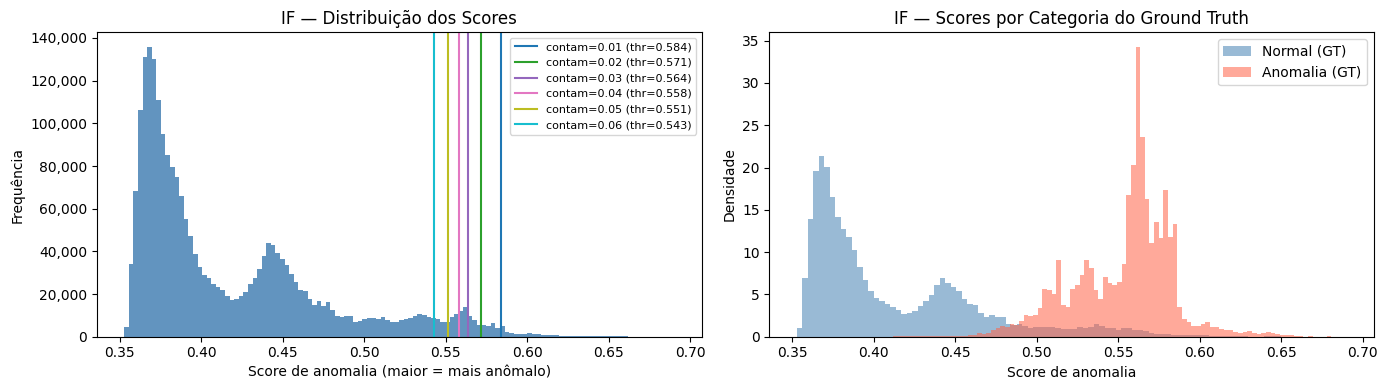

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
colors = plt.cm.tab10(np.linspace(0, 1, len(CONTAMINATIONS)))

axes[0].hist(if_scores, bins=120, color='steelblue', edgecolor='none', alpha=0.85)
for cont, color in zip(CONTAMINATIONS, colors):
    thr = np.percentile(if_scores, (1 - cont) * 100)
    axes[0].axvline(thr, color=color, linewidth=1.5,
                    label=f'contam={cont} (thr={thr:.3f})')
axes[0].set_title('IF — Distribuição dos Scores')
axes[0].set_xlabel('Score de anomalia (maior = mais anômalo)')
axes[0].set_ylabel('Frequência')
axes[0].legend(fontsize=8)
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))

axes[1].hist(if_scores[y_true == 0], bins=100, alpha=0.55,
             color='steelblue', label='Normal (GT)',   density=True)
axes[1].hist(if_scores[y_true == 1], bins=100, alpha=0.55,
             color='tomato',    label='Anomalia (GT)', density=True)
axes[1].set_title('IF — Scores por Categoria do Ground Truth')
axes[1].set_xlabel('Score de anomalia')
axes[1].set_ylabel('Densidade')
axes[1].legend()

plt.tight_layout()
plt.savefig(PROCESSED_DIR / 'fig_07_if_scores.png', dpi=120, bbox_inches='tight')
plt.show()

## 6. One-Class SVM

O One-Class SVM aprende um hiperplano no espaço transformado pelo kernel RBF que separa os dados de treinamento da origem. Pontos que caem do lado da origem — aqueles que o modelo nunca viu durante o treino — são classificados como anomalias.

**Diferença conceitual do IF:** o IF detecta raridade global (pontos em regiões esparsas), enquanto o OCSVM detecta desvio da fronteira de normalidade. O OCSVM é especialmente sensível a valores extremos em qualquer dimensão — como o IP com 20.377 requisições/hora.

**Limitação de escala:** o OCSVM tem complexidade quadrática no treino. Com 2,35 milhões de registros, treinar no dataset completo seria inviável. Estratégia: treinar em 50.000 registros normais (segundo o GT) e aplicar a predição no dataset inteiro.

In [9]:
OCSVM_TRAIN_SIZE = 50_000
np.random.seed(42)
train_idx     = np.random.choice(len(X), size=OCSVM_TRAIN_SIZE, replace=False)
X_train_ocsvm = X[train_idx]

n_contam_train = y_true[train_idx].sum()
print(f'OCSVM — amostragem aleatória para treino (sem uso do ground truth):')
print(f'  Amostrados para treino        : {len(train_idx):,}')
print(f'  Contaminação real na amostra  : {n_contam_train:,} ({n_contam_train/len(train_idx)*100:.2f}%)')
print(f'  Predição no dataset completo  : {X.shape[0]:,}')

OCSVM — amostragem aleatória para treino (sem uso do ground truth):
  Amostrados para treino        : 50,000
  Contaminação real na amostra  : 1,996 (3.99%)
  Predição no dataset completo  : 2,353,220


In [10]:
print('=== One-Class SVM ===')
print(f'  Treino  : {X_train_ocsvm.shape[0]:,} × {X_train_ocsvm.shape[1]} features')
print(f'  Kernel  : RBF   gamma=scale')
print()

t0 = time.time()
clf_ocsvm = OneClassSVM(kernel='rbf', nu=0.05, gamma='scale')
clf_ocsvm.fit(X_train_ocsvm)
ocsvm_scores = -clf_ocsvm.score_samples(X)   # invertido: maior = mais anômalo
all_scores['ocsvm'] = ocsvm_scores
t_ocsvm = time.time() - t0
print(f'  Treino + predição em {t_ocsvm:.1f}s')
print()

for nu in CONTAMINATIONS:
    thr    = np.percentile(ocsvm_scores, (1 - nu) * 100)
    y_pred = (ocsvm_scores >= thr).astype(int)
    m      = compute_metrics(y_true, y_pred, 'One-Class SVM', nu)
    m['tempo_s'] = round(t_ocsvm, 1)
    all_results.append(m)
    all_pred_cols[f'ocsvm_{nu}'] = y_pred
    print(f'  nu={nu:.2f}     | detectadas={m["detectadas"]:>7,} | '
          f'precisão={m["precisao"]:.3f} | recall={m["recall"]:.3f} | F1={m["f1"]:.3f}')

=== One-Class SVM ===
  Treino  : 50,000 × 37 features
  Kernel  : RBF   gamma=scale



KeyboardInterrupt: 

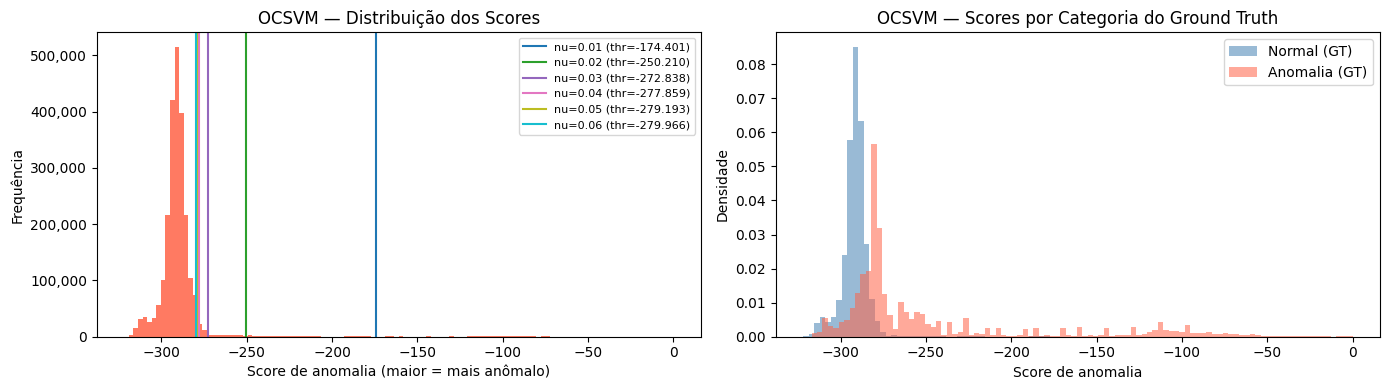

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(ocsvm_scores, bins=120, color='tomato', edgecolor='none', alpha=0.85)
for nu, color in zip(CONTAMINATIONS, colors):
    thr = np.percentile(ocsvm_scores, (1 - nu) * 100)
    axes[0].axvline(thr, color=color, linewidth=1.5,
                    label=f'nu={nu} (thr={thr:.3f})')
axes[0].set_title('OCSVM — Distribuição dos Scores')
axes[0].set_xlabel('Score de anomalia (maior = mais anômalo)')
axes[0].set_ylabel('Frequência')
axes[0].legend(fontsize=8)
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))

axes[1].hist(ocsvm_scores[y_true == 0], bins=100, alpha=0.55,
             color='steelblue', label='Normal (GT)',   density=True)
axes[1].hist(ocsvm_scores[y_true == 1], bins=100, alpha=0.55,
             color='tomato',    label='Anomalia (GT)', density=True)
axes[1].set_title('OCSVM — Scores por Categoria do Ground Truth')
axes[1].set_xlabel('Score de anomalia')
axes[1].set_ylabel('Densidade')
axes[1].legend()

plt.tight_layout()
plt.savefig(PROCESSED_DIR / 'fig_08_ocsvm_scores.png', dpi=120, bbox_inches='tight')
plt.show()

## 7. Comparação dos Modelos

### 7.1 — Tabela de Métricas

In [ ]:
results_df = pd.DataFrame(all_results)[[
    'modelo','contamination','detectadas','tp','fp','fn','precisao','recall','f1','tempo_s'
]]

W = 98
print('=' * W)
print('  ISOLATION FOREST  vs  ONE-CLASS SVM')
print('=' * W)
print(f'{"Modelo":<20} {"Contam":>7} {"Detectadas":>11} '
      f'{"TP":>8} {"FP":>8} {"FN":>8} '
      f'{"Precisão":>9} {"Recall":>8} {"F1":>8} {"Tempo":>7}')
print('─' * W)

prev_model = None
for _, r in results_df.iterrows():
    if prev_model and r['modelo'] != prev_model:
        print('─' * W)
    prev_model = r['modelo']
    print(f'{r["modelo"]:<20} {r["contamination"]:>7.2f} {r["detectadas"]:>11,} '
          f'{r["tp"]:>8,} {r["fp"]:>8,} {r["fn"]:>8,} '
          f'{r["precisao"]:>9.3f} {r["recall"]:>8.3f} {r["f1"]:>8.3f} '
          f'{r["tempo_s"]:>6.1f}s')

print('=' * W)
print(f'Ground truth: {n_gt:,} anomalias ({pct_gt:.2f}%)   Dataset: {len(y_true):,} registros')
print()
print('Melhor F1 por modelo:')
for nome in results_df['modelo'].unique():
    b = results_df[results_df['modelo'] == nome].nlargest(1, 'f1').iloc[0]
    print(f'  {nome:<20}  F1={b["f1"]:.3f}  '
          f'(contam={b["contamination"]:.2f}, precisão={b["precisao"]:.3f}, recall={b["recall"]:.3f})')

  ISOLATION FOREST  vs  ONE-CLASS SVM
Modelo                Contam  Detectadas       TP       FP       FN  Precisão   Recall       F1   Tempo
──────────────────────────────────────────────────────────────────────────────────────────────────
Isolation Forest        0.01      23,569    9,330   14,239   81,970     0.396    0.102    0.162   41.0s
Isolation Forest        0.02      47,220   24,670   22,550   66,630     0.522    0.270    0.356   41.0s
Isolation Forest        0.03      70,626   37,132   33,494   54,168     0.526    0.407    0.459   41.0s
Isolation Forest        0.04      94,159   50,571   43,588   40,729     0.537    0.554    0.545   41.0s
Isolation Forest        0.05     117,661   58,426   59,235   32,874     0.497    0.640    0.559   41.0s
Isolation Forest        0.06     141,199   63,539   77,660   27,761     0.450    0.696    0.547   41.0s
──────────────────────────────────────────────────────────────────────────────────────────────────
One-Class SVM           0.01      23

### 7.2 — Curvas Precisão-Recall e AUC-PR

A Curva PR mostra o tradeoff entre precisão e recall em **todos os thresholds possíveis** — não apenas nos 3 pontos testados. É mais informativa que a curva ROC para datasets desbalanceados.

**AUC-PR** resume o desempenho global em um único número. Um classificador aleatório teria AUC-PR ≈ 0.048 (proporção de anomalias no dataset). Quanto mais próximo de 1, melhor.

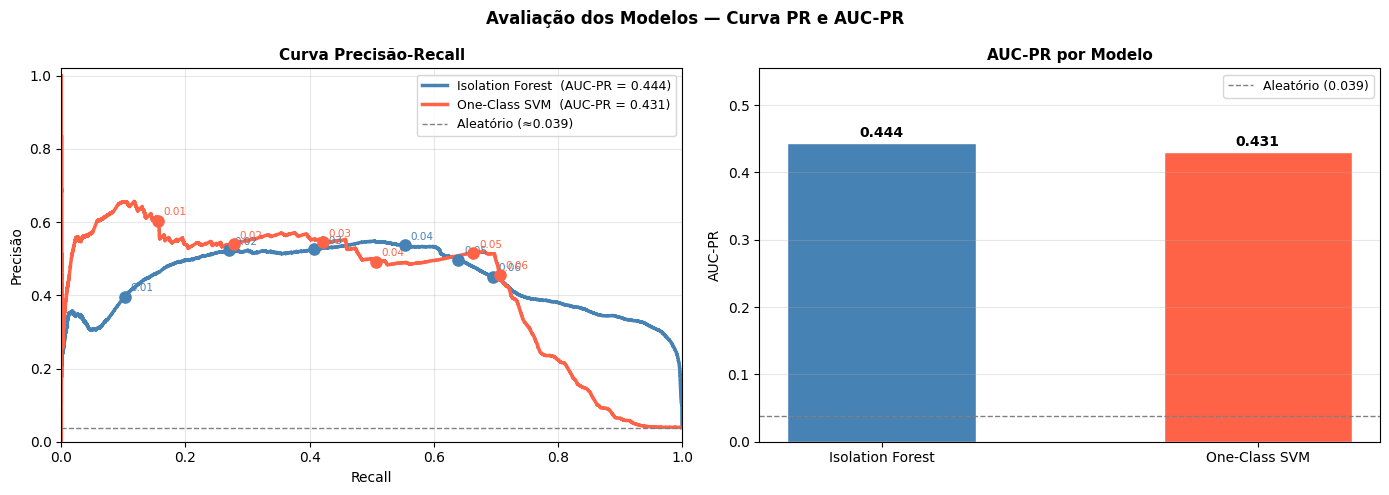

AUC-PR:
  Isolation Forest    : 0.4438  (11.4× acima do classificador aleatório)
  One-Class SVM       : 0.4306  (11.1× acima do classificador aleatório)


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors = {'if': 'steelblue', 'ocsvm': 'tomato'}
labels = {'if': 'Isolation Forest', 'ocsvm': 'One-Class SVM'}
auc_prs = {}

for key, scores in all_scores.items():
    prec_c, rec_c, _ = precision_recall_curve(y_true, scores)
    auc_pr = auc(rec_c, prec_c)
    auc_prs[key] = auc_pr
    axes[0].plot(rec_c, prec_c, color=colors[key], linewidth=2.5,
                 label=f'{labels[key]}  (AUC-PR = {auc_pr:.3f})')

    for cont in CONTAMINATIONS:
        thr    = np.percentile(scores, (1 - cont) * 100)
        y_pred = (scores >= thr).astype(int)
        p_pt   = precision_score(y_true, y_pred, zero_division=0)
        r_pt   = recall_score(   y_true, y_pred, zero_division=0)
        axes[0].scatter(r_pt, p_pt, color=colors[key], s=65, zorder=5)
        axes[0].annotate(f'{cont}', (r_pt, p_pt),
                         textcoords='offset points', xytext=(4, 4),
                         fontsize=7.5, color=colors[key])

axes[0].axhline(pct_gt / 100, color='gray', linestyle='--', linewidth=1,
                label=f'Aleatório (≈{pct_gt/100:.3f})')
axes[0].set_title('Curva Precisão-Recall', fontweight='bold', fontsize=11)
axes[0].set_xlabel('Recall')
axes[0].set_ylabel('Precisão')
axes[0].set_xlim(0, 1)
axes[0].set_ylim(0, 1.02)
axes[0].legend(fontsize=9)
axes[0].grid(alpha=0.3)

bar_keys    = list(auc_prs.keys())
bar_vals    = [auc_prs[k] for k in bar_keys]
bar_labels  = [labels[k]  for k in bar_keys]
bar_colors  = [colors[k]  for k in bar_keys]
bars = axes[1].bar(bar_labels, bar_vals, color=bar_colors, edgecolor='white', width=0.5)
axes[1].axhline(pct_gt / 100, color='gray', linestyle='--', linewidth=1,
                label=f'Aleatório ({pct_gt/100:.3f})')
for bar, val in zip(bars, bar_vals):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.004,
                 f'{val:.3f}', ha='center', va='bottom', fontweight='bold', fontsize=10)
axes[1].set_title('AUC-PR por Modelo', fontweight='bold', fontsize=11)
axes[1].set_ylabel('AUC-PR')
axes[1].set_ylim(0, max(bar_vals) * 1.25)
axes[1].legend(fontsize=9)
axes[1].grid(axis='y', alpha=0.3)

plt.suptitle('Avaliação dos Modelos — Curva PR e AUC-PR',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(PROCESSED_DIR / 'fig_09_pr_curves.png', dpi=120, bbox_inches='tight')
plt.show()

print('AUC-PR:')
for k, v in auc_prs.items():
    print(f'  {labels[k]:<20}: {v:.4f}  '
          f'({v/(pct_gt/100):.1f}× acima do classificador aleatório)')

### 7.3 — Métricas por Contamination e Matrizes de Confusão

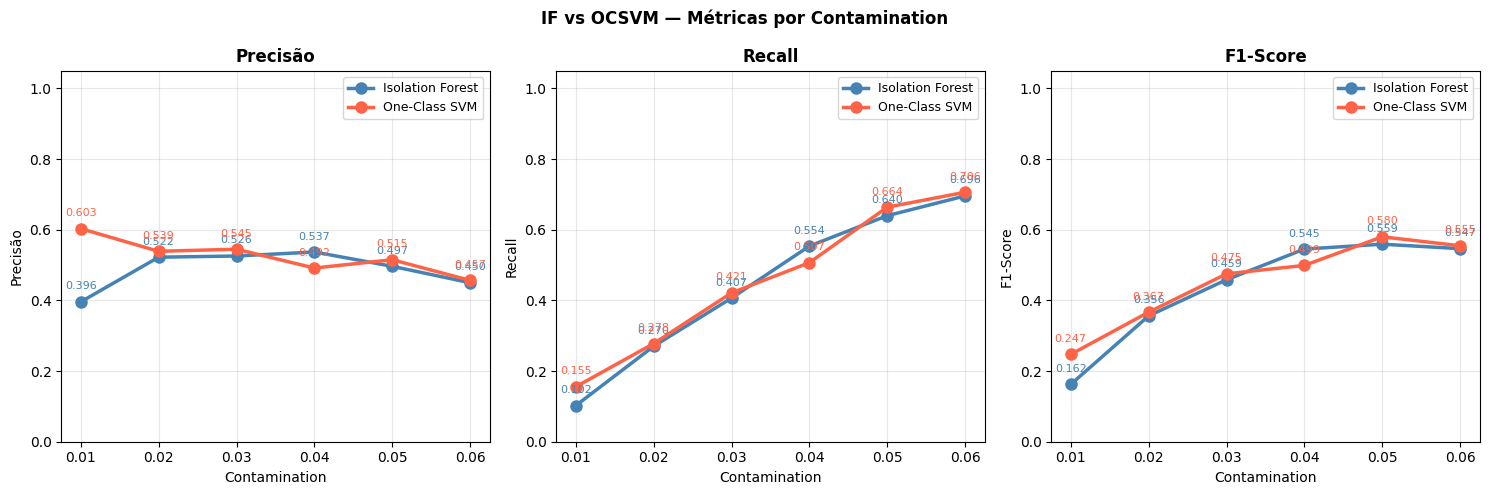

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
model_colors = {'Isolation Forest': 'steelblue', 'One-Class SVM': 'tomato'}

for ax, (metric, name) in zip(axes, [('precisao','Precisão'),('recall','Recall'),('f1','F1-Score')]):
    for modelo, cor in model_colors.items():
        sub = results_df[results_df['modelo'] == modelo].sort_values('contamination')
        ax.plot(sub['contamination'], sub[metric], marker='o',
                color=cor, linewidth=2.5, markersize=8, label=modelo)
        for _, row in sub.iterrows():
            ax.annotate(f'{row[metric]:.3f}', (row['contamination'], row[metric]),
                        textcoords='offset points', xytext=(0, 9),
                        ha='center', fontsize=8, color=cor)
    ax.set_title(name, fontsize=12, fontweight='bold')
    ax.set_xlabel('Contamination')
    ax.set_ylabel(name)
    ax.set_ylim(0, 1.05)
    ax.set_xticks(CONTAMINATIONS)
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3)

plt.suptitle('IF vs OCSVM — Métricas por Contamination', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(PROCESSED_DIR / 'fig_10_metrics_comparison.png', dpi=120, bbox_inches='tight')
plt.show()

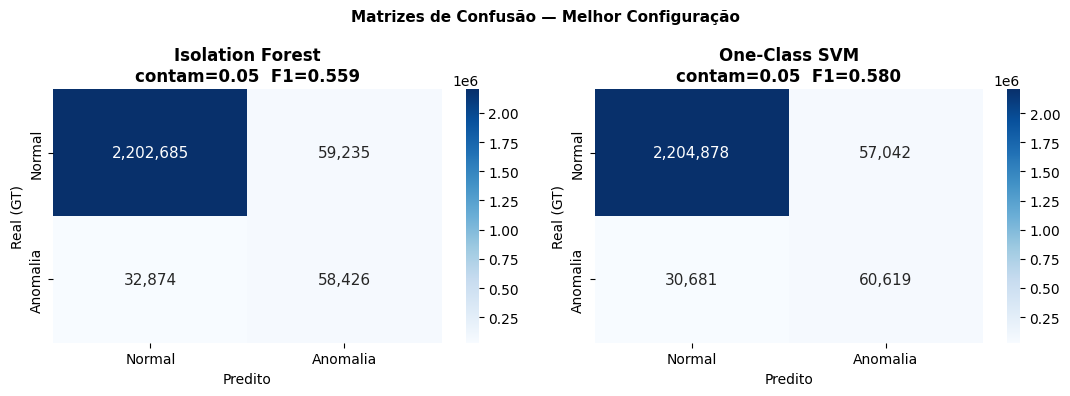

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, (nome, prefixo) in zip(axes, [('Isolation Forest','if'), ('One-Class SVM','ocsvm')]):
    best_cont = results_df[results_df['modelo'] == nome].nlargest(1,'f1')['contamination'].values[0]
    y_pred    = all_pred_cols[f'{prefixo}_{best_cont}']
    cm        = confusion_matrix(y_true, y_pred)
    f1_val    = results_df[
        (results_df['modelo'] == nome) & (results_df['contamination'] == best_cont)
    ]['f1'].values[0]
    sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', ax=ax,
                xticklabels=['Normal','Anomalia'],
                yticklabels=['Normal','Anomalia'], annot_kws={'size': 11})
    ax.set_title(f'{nome}\ncontam={best_cont}  F1={f1_val:.3f}', fontweight='bold')
    ax.set_xlabel('Predito')
    ax.set_ylabel('Real (GT)')

plt.suptitle('Matrizes de Confusão — Melhor Configuração', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig(PROCESSED_DIR / 'fig_11_confusion_matrices.png', dpi=120, bbox_inches='tight')
plt.show()

## 8. Análise Qualitativa

### 8.1 — Monta o DataFrame de Análise

In [ ]:
best_if_cont    = results_df[results_df['modelo']=='Isolation Forest'].nlargest(1,'f1')['contamination'].values[0]
best_ocsvm_cont = results_df[results_df['modelo']=='One-Class SVM'].nlargest(1,'f1')['contamination'].values[0]

analysis = logs[['ip','timestamp','host','http_method','uri','status','bytes','user_agent']].copy()
analysis['gt_anomaly']  = y_true
analysis['gt_reason']   = reasons.values
analysis['if_score']    = if_scores
analysis['ocsvm_score'] = ocsvm_scores
analysis['pred_if']     = all_pred_cols[f'if_{best_if_cont}']
analysis['pred_ocsvm']  = all_pred_cols[f'ocsvm_{best_ocsvm_cont}']
analysis['n_models']    = analysis['pred_if'] + analysis['pred_ocsvm']

gt_mask = analysis['gt_anomaly'] == 1

print(f'IF  : melhor contam={best_if_cont}')
print(f'OCSVM: melhor contam={best_ocsvm_cont}')

IF  : melhor contam=0.05
OCSVM: melhor contam=0.05


### 8.2 — Captura por Tipo de Anomalia

In [ ]:
masks = {
    'uri_attack_pattern':   mask_1,
    'suspicious_extension': mask_2,
    'known_scanner_ua':     mask_3,
    'flood_high_error':     mask_4,
    'excessive_encoding':   mask_5,
}

p_if = analysis['pred_if'].values == 1
p_oc = analysis['pred_ocsvm'].values == 1

rows = []
for nome, m in masks.items():
    m = m.values.astype(bool)
    total = m.sum()
    rows.append({
        'criterio'    : nome,
        'total'       : total,
        'recall_if'   : (m & p_if).sum() / total,
        'recall_ocsvm': (m & p_oc).sum() / total,
        'recall_ambos': (m & p_if & p_oc).sum() / total,
        'nenhum'      : (m & ~p_if & ~p_oc).sum() / total,
    })
recall_df = pd.DataFrame(rows)
display(recall_df.style.format({c: '{:.1%}' for c in recall_df.columns[2:]}))

# Sobreposição entre critérios (diagonal = total do critério)
M = pd.DataFrame({k: v.values.astype(int) for k, v in masks.items()})
display(M.T.dot(M))
print('olha olha')

,criterio,total,recall_if,recall_ocsvm,recall_ambos,nenhum
0,uri_attack_pattern,10019,64.1%,25.6%,25.0%,35.4%
1,suspicious_extension,7914,25.9%,14.2%,11.1%,71.0%
2,known_scanner_ua,49345,88.0%,72.0%,71.5%,11.5%
3,flood_high_error,47938,82.2%,89.9%,76.5%,4.4%
4,excessive_encoding,15780,40.4%,91.8%,39.0%,6.8%


,uri_attack_pattern,suspicious_extension,known_scanner_ua,flood_high_error,excessive_encoding
uri_attack_pattern,10019,197,393,761,182
suspicious_extension,197,7914,152,772,0
known_scanner_ua,393,152,49345,37271,3
flood_high_error,761,772,37271,47938,0
excessive_encoding,182,0,3,0,15780


olha olha


In [ ]:
print('=== Captura por Tipo de Anomalia ===')
print(f'{"Tipo":<38} {"Total":>7}  {"IF":>14}  {"OCSVM":>14}  {"Ambos":>12}')
print('─' * 88)

tipo_rows = []
for reason in ['uri_attack_pattern','suspicious_extension',
               'known_scanner_ua','flood_high_error','excessive_encoding']:
    mask_r    = gt_mask & (analysis['gt_reason'] == reason)
    total     = mask_r.sum()
    if total == 0:
        continue
    cap_if    = (mask_r & (analysis['pred_if']    == 1)).sum()
    cap_ocsvm = (mask_r & (analysis['pred_ocsvm'] == 1)).sum()
    cap_both  = (mask_r & (analysis['n_models']   == 2)).sum()
    tipo_rows.append({'tipo': reason,'total': total,
                      'if': cap_if,'ocsvm': cap_ocsvm,'ambos': cap_both})
    print(f'{reason:<38} {total:>7,}  '
          f'{cap_if:>6,} ({cap_if/total*100:4.1f}%)  '
          f'{cap_ocsvm:>6,} ({cap_ocsvm/total*100:4.1f}%)  '
          f'{cap_both:>5,} ({cap_both/total*100:4.1f}%)')

print('─' * 88)
cap_if_t  = (gt_mask & (analysis['pred_if']    == 1)).sum()
cap_oc_t  = (gt_mask & (analysis['pred_ocsvm'] == 1)).sum()
cap_bth   = (gt_mask & (analysis['n_models']   == 2)).sum()
cap_any   = (gt_mask & (analysis['n_models']   >= 1)).sum()
print(f'{"TOTAL":<38} {n_gt:>7,}  '
      f'{cap_if_t:>6,} ({cap_if_t/n_gt*100:4.1f}%)  '
      f'{cap_oc_t:>6,} ({cap_oc_t/n_gt*100:4.1f}%)  '
      f'{cap_bth:>5,} ({cap_bth/n_gt*100:4.1f}%)')
print(f'Capturado por qualquer modelo   : {cap_any:,} ({cap_any/n_gt*100:.1f}%)')

=== Captura por Tipo de Anomalia ===
Tipo                                     Total              IF           OCSVM         Ambos
────────────────────────────────────────────────────────────────────────────────────────
uri_attack_pattern                      10,019   6,424 (64.1%)   2,560 (25.6%)  2,508 (25.0%)
suspicious_extension                     7,717   1,875 (24.3%)   1,062 (13.8%)    822 (10.7%)
known_scanner_ua                        48,800  42,902 (87.9%)  35,474 (72.7%)  35,233 (72.2%)
flood_high_error                         9,166     977 (10.7%)   7,112 (77.6%)    939 (10.2%)
excessive_encoding                      15,598   6,248 (40.1%)  14,411 (92.4%)  6,113 (39.2%)
────────────────────────────────────────────────────────────────────────────────────────
TOTAL                                   91,300  58,426 (64.0%)  60,619 (66.4%)  45,615 (50.0%)
Capturado por qualquer modelo   : 73,430 (80.4%)


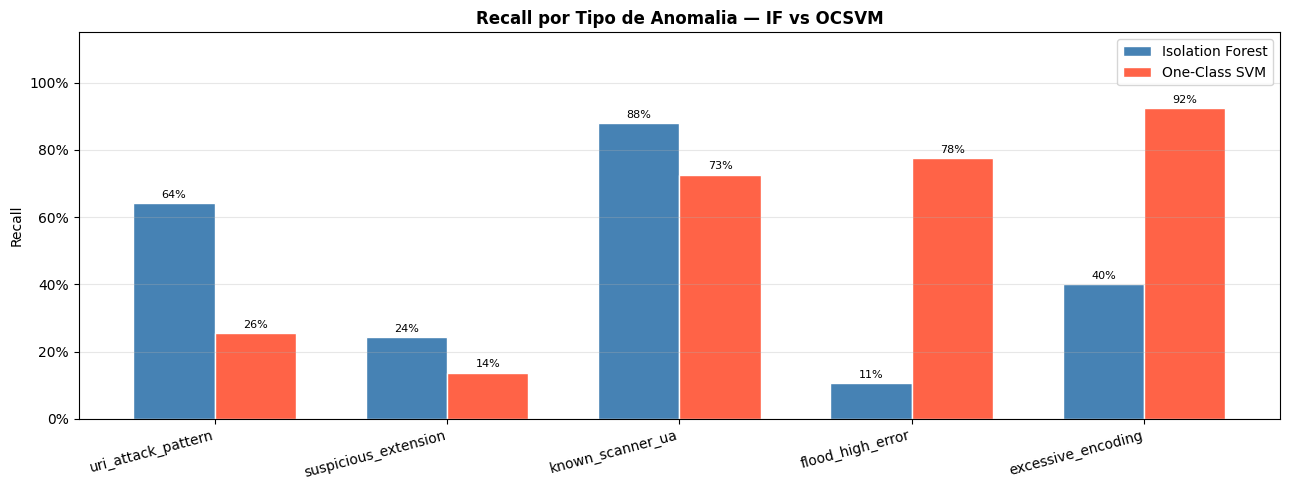

In [ ]:
ts = pd.DataFrame(tipo_rows)
ts['recall_if']    = ts['if']    / ts['total']
ts['recall_ocsvm'] = ts['ocsvm'] / ts['total']

x, w = np.arange(len(ts)), 0.35
fig, ax = plt.subplots(figsize=(13, 5))
b1 = ax.bar(x - w/2, ts['recall_if'],    w, label='Isolation Forest', color='steelblue', edgecolor='white')
b2 = ax.bar(x + w/2, ts['recall_ocsvm'], w, label='One-Class SVM',    color='tomato',    edgecolor='white')
for bar in list(b1) + list(b2):
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 0.01, f'{h:.0%}',
            ha='center', va='bottom', fontsize=8)
ax.set_title('Recall por Tipo de Anomalia — IF vs OCSVM', fontweight='bold', fontsize=12)
ax.set_ylabel('Recall')
ax.set_xticks(x)
ax.set_xticklabels(ts['tipo'], rotation=15, ha='right')
ax.set_ylim(0, 1.15)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(PROCESSED_DIR / 'fig_12_recall_by_type.png', dpi=120, bbox_inches='tight')
plt.show()

### 8.3 — Concordância entre Modelos

In [ ]:
high_conf = analysis[analysis['n_models'] == 2].copy()
only_if   = analysis[(analysis['pred_if'] == 1) & (analysis['pred_ocsvm'] == 0)]
only_oc   = analysis[(analysis['pred_if'] == 0) & (analysis['pred_ocsvm'] == 1)]

print('=== Concordância entre Modelos ===')
print(f'  Detectadas por AMBOS (alta confiança) : {len(high_conf):>8,}')
print(f'  Detectadas só pelo IF                 : {len(only_if):>8,}')
print(f'  Detectadas só pelo OCSVM              : {len(only_oc):>8,}')
print(f'  Não detectadas por nenhum             : {(analysis["n_models"]==0).sum():>8,}')
print()
print(f'Anomalias de alta confiança (ambos os modelos):')
print(f'  Total                   : {len(high_conf):,}')
print(f'  No ground truth         : {high_conf["gt_anomaly"].sum():,} '
      f'({high_conf["gt_anomaly"].mean()*100:.1f}%)')
print(f'  Fora do ground truth    : {(high_conf["gt_anomaly"]==0).sum():,} '
      f'(possíveis anomalias não cobertas pelas regras do GT)')
print()
print('Amostra de anomalias de alta confiança:')
display(
    high_conf[['ip','host','uri','status','user_agent','gt_anomaly','gt_reason']]
    .sample(min(12, len(high_conf)), random_state=42)
    .assign(uri=lambda d: d['uri'].str[:65], user_agent=lambda d: d['user_agent'].str[:45])
    .reset_index(drop=True)
)

=== Concordância entre Modelos ===
  Detectadas por AMBOS (alta confiança) :   51,310
  Detectadas só pelo IF                 :   66,351
  Detectadas só pelo OCSVM              :   66,351
  Não detectadas por nenhum             : 2,169,208

Anomalias de alta confiança (ambos os modelos):
  Total                   : 51,310
  No ground truth         : 45,615 (88.9%)
  Fora do ground truth    : 5,695 (possíveis anomalias não cobertas pelas regras do GT)

Amostra de anomalias de alta confiança:


,ip,host,uri,status,user_agent,gt_anomaly,gt_reason
0,186.233.190.218,www.uem.br,/nk9,404,gobuster/3.5,1,known_scanner_ua
1,186.233.190.218,www.uem.br,/byteme,404,gobuster/3.5,1,known_scanner_ua
2,186.233.190.218,www.uem.br,/buddylist,404,gobuster/3.5,1,known_scanner_ua
3,186.233.190.218,www.uem.br,/lipetsk,404,gobuster/3.5,1,known_scanner_ua
4,45.71.104.191,www.uem.br,/sk,404,gobuster/3.5,1,known_scanner_ua
5,40.77.167.196,sites.uem.br,/pcf/courses?set_language=pt-br&month:int=2&or...,200,"Mozilla/5.0 AppleWebKit/537.36 (KHTML, like G",1,excessive_encoding
6,45.71.104.191,www.uem.br,/missy,404,gobuster/3.5,1,known_scanner_ua
7,198.71.236.20,www.ctc.uem.br,/wwwroot.bak,404,Mozilla/5.0 (Windows NT 10.0; WOW64; rv:56.0),1,suspicious_extension
8,198.71.236.20,www.dfe.uem.br,/phpMyAdmin-2.5.4/,404,Mozilla/5.0 (Windows NT 10.0; WOW64; rv:56.0),1,uri_attack_pattern
9,43.153.133.148,www.dhi.uem.br,/lock360.php?daksldlkdsadas=1,404,wp_is_mobile,0,


### 8.4 — Caso de Estudo: IP com Comportamento de Flood (`186.233.190.218`)

In [ ]:
IP_FLOOD = '186.233.190.218'
flood_df = analysis[analysis['ip'] == IP_FLOOD].copy()

print(f'=== Caso de Estudo: {IP_FLOOD} ===')
print(f'  Requisições no dataset    : {len(flood_df):,}')
print(f'  Detectadas pelo IF        : {flood_df["pred_if"].sum():,} ({flood_df["pred_if"].mean()*100:.1f}%)')
print(f'  Detectadas pelo OCSVM     : {flood_df["pred_ocsvm"].sum():,} ({flood_df["pred_ocsvm"].mean()*100:.1f}%)')
print(f'  No ground truth (flood)   : {flood_df["gt_anomaly"].sum():,} ({flood_df["gt_anomaly"].mean()*100:.1f}%)')
print()
print('Status HTTP:')
display(flood_df['status'].value_counts().head(6))
print('\nTop 10 URIs:')
display(
    flood_df['uri'].value_counts().head(10).reset_index()
    .rename(columns={'count':'acessos'})
    .assign(uri=lambda d: d['uri'].str[:70])
)

=== Caso de Estudo: 186.233.190.218 ===
  Requisições no dataset    : 20,494
  Detectadas pelo IF        : 20,274 (98.9%)
  Detectadas pelo OCSVM     : 16,750 (81.7%)
  No ground truth (flood)   : 20,381 (99.4%)

Status HTTP:


status
404    20234
200      223
302       18
301       15
500        2
400        2
Name: count, dtype: int64


Top 10 URIs:


,uri,acessos
0,/collective.js.jqueryui.custom.min.css?version...,11
1,/imagens/gestao_2022_200x95-1.png/@@images/6e3...,10
2,/parana.png,10
3,/@@site-logo/logo_uem_50anos_181x65.png,10
4,/collective.js.jqueryui.custom.min.js?version=...,10
5,/,4
6,/conteudo-exemplo/e-mec/@@images/62eaf5f4-8c9e...,3
7,/noticias-externas/noticias-uem/hospital-unive...,3
8,/imagens/retorno.png/@@images/395ae434-c120-4e...,3
9,/imagens/biosseguranca.png/@@images/64f2ee37-a...,3


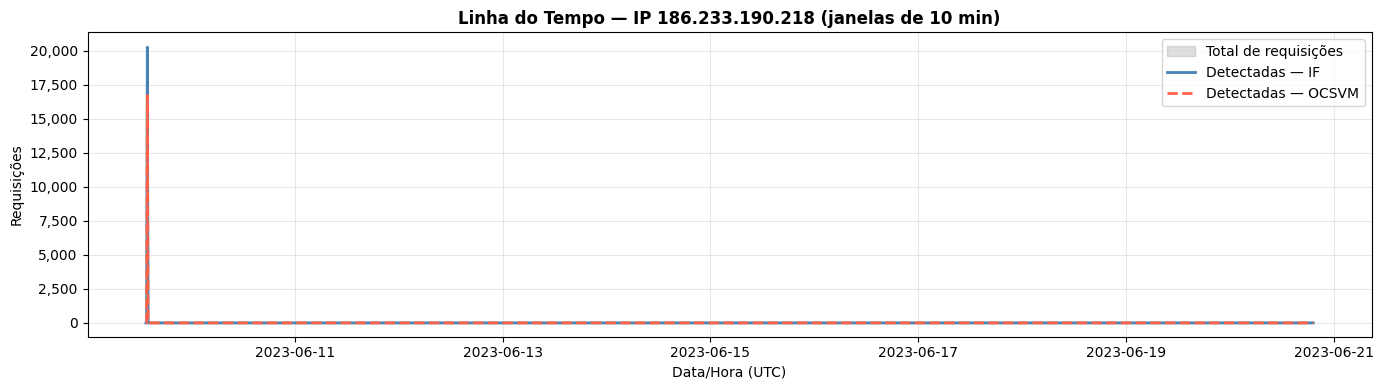

In [ ]:
flood_ts = (
    flood_df.set_index('timestamp')
    .resample('10min')[['pred_if','pred_ocsvm','gt_anomaly']]
    .agg({'pred_if':'sum','pred_ocsvm':'sum','gt_anomaly':'count'})
    .rename(columns={'gt_anomaly':'total'})
)

fig, ax = plt.subplots(figsize=(14, 4))
ax.fill_between(flood_ts.index, flood_ts['total'],
                alpha=0.25, color='gray', label='Total de requisições')
ax.plot(flood_ts.index, flood_ts['pred_if'],
        color='steelblue', linewidth=2, label='Detectadas — IF')
ax.plot(flood_ts.index, flood_ts['pred_ocsvm'],
        color='tomato',    linewidth=2, linestyle='--', label='Detectadas — OCSVM')
ax.set_title(f'Linha do Tempo — IP {IP_FLOOD} (janelas de 10 min)', fontweight='bold')
ax.set_xlabel('Data/Hora (UTC)')
ax.set_ylabel('Requisições')
ax.legend()
ax.grid(alpha=0.3)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
plt.tight_layout()
plt.savefig(PROCESSED_DIR / 'fig_13_flood_timeline.png', dpi=120, bbox_inches='tight')
plt.show()

In [ ]:
m = (analysis['ip'] == IP_FLOOD).values
cols = ['ip_req_count_prev1h', 'ip_error_rate_prev1h']
sub = features_raw.loc[m, cols]

print(sub.loc[sub['ip_req_count_prev1h'].idxmax()])   # linha do pico
print('Máximo global de ip_req_count_prev1h:', features_raw['ip_req_count_prev1h'].max())

ip_req_count_prev1h     20431.000000
ip_error_rate_prev1h        0.990162
Name: 251624, dtype: float64
Máximo global de ip_req_count_prev1h: 20514


In [ ]:
i = features_raw['ip_req_count_prev1h'].idxmax()
print(logs.loc[i, 'ip'], features_raw.loc[i, ['ip_req_count_prev1h', 'ip_error_rate_prev1h']])

45.71.104.191 ip_req_count_prev1h     20514.000000
ip_error_rate_prev1h        0.995564
Name: 334649, dtype: float64


### 8.5 — Caso de Estudo: Scanners de WordPress num Servidor Plone

A UEM usa Plone como CMS. Qualquer acesso a `/wp-login.php` ou `/wp-admin` é por definição um scanner externo — WordPress não existe neste servidor. Este caso ilustra como o conhecimento do ambiente é essencial para interpretar anomalias.

In [ ]:
wp_df = analysis[analysis['uri'].str.contains('/wp-', na=False, case=False)].copy()

print(f'=== Acessos a Rotas WordPress (servidor usa Plone) ===')
print(f'  Total de acessos   : {len(wp_df):,}')
print(f'  IPs únicos         : {wp_df["ip"].nunique():,}')
print(f'  Detectados pelo IF : {wp_df["pred_if"].sum():,} ({wp_df["pred_if"].mean()*100:.1f}%)')
print(f'  Detectados OCSVM   : {wp_df["pred_ocsvm"].sum():,} ({wp_df["pred_ocsvm"].mean()*100:.1f}%)')
print()
print('Top 10 URIs WordPress:')
display(
    wp_df.groupby('uri').agg(
        acessos=('uri','count'),
        ips_unicos=('ip','nunique'),
        status_principal=('status', lambda s: s.mode()[0])
    ).sort_values('acessos', ascending=False).head(20).reset_index()
    .assign(uri=lambda d: d['uri'].str[:200])
)

=== Acessos a Rotas WordPress (servidor usa Plone) ===
  Total de acessos   : 112,033
  IPs únicos         : 7,747
  Detectados pelo IF : 8,610 (7.7%)
  Detectados OCSVM   : 1,918 (1.7%)

Top 10 URIs WordPress:


,uri,acessos,ips_unicos,status_principal
0,/comunicauem/wp-comments-post.php,8266,3154,409
1,/comunicauem/wp-content/themes/15zine/library/...,2428,2112,200
2,/comunicauem/wp-content/themes/15zine/library/...,2213,2114,200
3,/comunicauem/wp-content/themes/15zine/library/...,2190,2097,200
4,/comunicauem/wp-content/themes/15zine/library/...,2178,2081,200
5,/comunicauem/wp-includes/js/jquery/jquery-migr...,2174,2079,200
6,/comunicauem/wp-includes/js/jquery/jquery.js?v...,2171,2075,200
7,/comunicauem/wp-content/uploads/2016/11/logo-c...,2148,2047,200
8,/comunicauem/wp-includes/js/comment-reply.min....,2142,1974,200
9,/comunicauem/wp-content/themes/15zine/library/...,2072,1981,200


### 8.6 — Falsos Negativos: o que os modelos não capturaram

In [ ]:
fn_df = analysis[gt_mask & (analysis['n_models'] == 0)]
print(f'=== Falsos Negativos — Anomalias do GT não detectadas por nenhum modelo ===')
print(f'  Total: {len(fn_df):,} de {n_gt:,} ({len(fn_df)/n_gt*100:.1f}%)')
print()
print('Por tipo:')
display(fn_df['gt_reason'].value_counts())
print()
print('Exemplos:')
display(
    fn_df[['ip','host','uri','status','gt_reason']]
    .sample(min(10, len(fn_df)), random_state=42)
    .assign(uri=lambda d: d['uri'].str[:65])
    .reset_index(drop=True)
)
print()
print('Interpretação:')
print('  Falsos negativos de suspicious_extension geralmente têm outras features')
print('  completamente normais (status 200, UA de browser, sem flood). Isso indica')
print('  que extensão suspeita sozinha não é suficiente para separar anomalias —')
print('  sem informação adicional do conteúdo da resposta, esses registros são')
print('  indistinguíveis do tráfego legítimo para os algoritmos testados.')

=== Falsos Negativos — Anomalias do GT não detectadas por nenhum modelo ===
  Total: 17,870 de 91,300 (19.6%)

Por tipo:


gt_reason
known_scanner_ua        5657
suspicious_extension    5602
uri_attack_pattern      3543
flood_high_error        2016
excessive_encoding      1052
Name: count, dtype: int64


Exemplos:


,ip,host,uri,status,gt_reason
0,128.199.206.4,www.uem.br,/,200,known_scanner_ua
1,198.71.236.20,www.dqi.uem.br,/adminer-4.1.0.php,404,flood_high_error
2,41.216.188.168,www.caua.uem.br,/wp-admin/user/,404,uri_attack_pattern
3,79.124.49.10,www.ccb.uem.br,/web/.env,404,suspicious_extension
4,105.214.33.127,www.dfe.uem.br,/wp-login.php?action=register,404,uri_attack_pattern
5,198.71.236.20,www.uem.br,/public_html.bak,404,suspicious_extension
6,14.116.156.162,www.dem.uem.br,/?author=16,200,known_scanner_ua
7,14.18.110.73,www.ppi.uem.br,/?author=3,200,known_scanner_ua
8,206.41.164.94,www.dfe.uem.br,/wp-login.php?action=register,404,uri_attack_pattern
9,79.124.49.10,dbc.uem.br,/admin/sendgrid.env,301,suspicious_extension



Interpretação:
  Falsos negativos de suspicious_extension geralmente têm outras features
  completamente normais (status 200, UA de browser, sem flood). Isso indica
  que extensão suspeita sozinha não é suficiente para separar anomalias —
  sem informação adicional do conteúdo da resposta, esses registros são
  indistinguíveis do tráfego legítimo para os algoritmos testados.


### 8.7 — Linha do Tempo das Anomalias (15 dias)

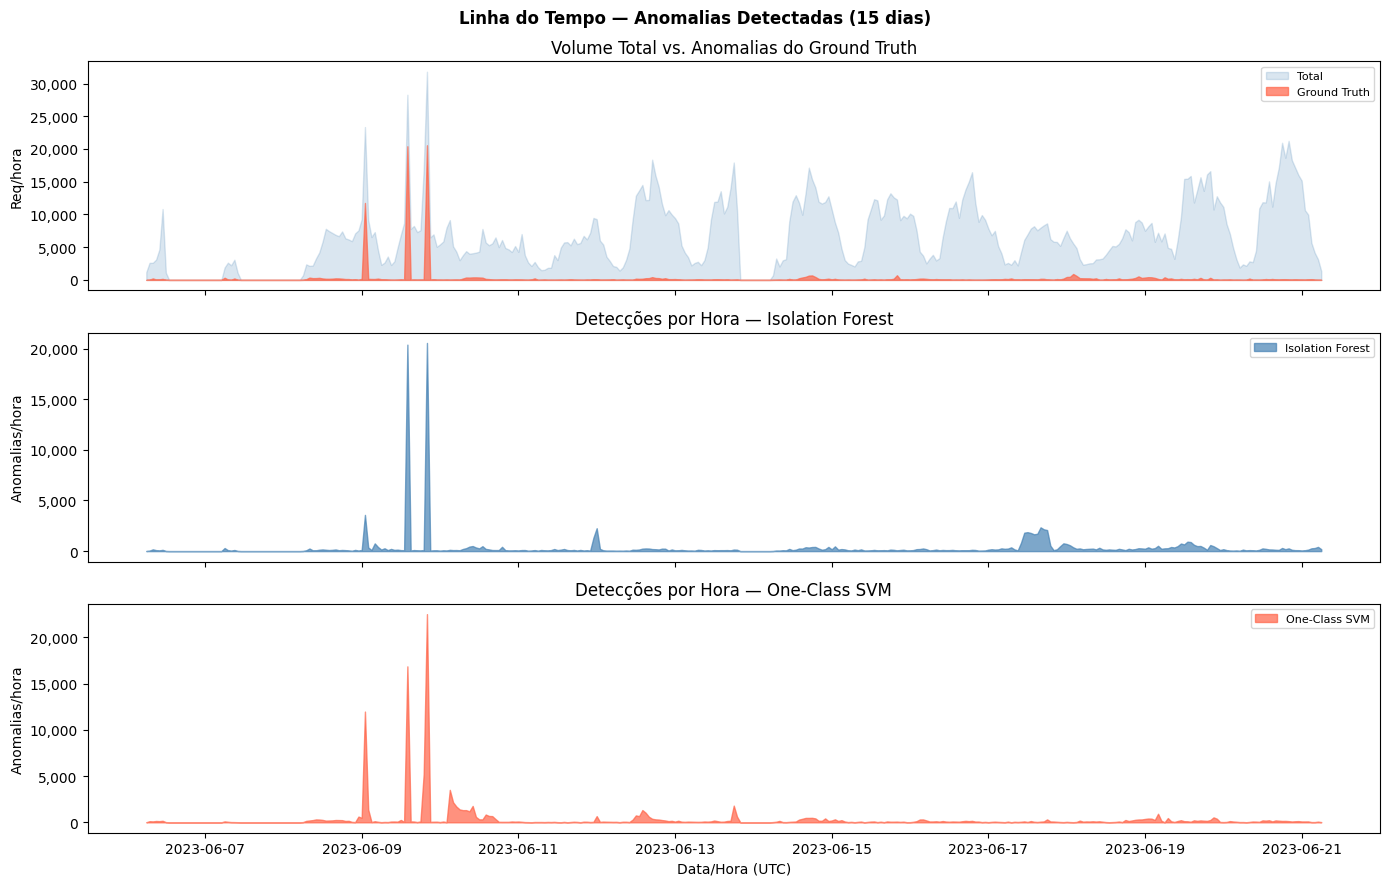

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
ts_base = analysis.set_index('timestamp')

# Painel 1: volume total vs GT
ts1 = ts_base.resample('1h')['gt_anomaly'].agg(['count','sum'])
ts1.columns = ['total','gt']
axes[0].fill_between(ts1.index, ts1['total'], alpha=0.2, color='steelblue', label='Total')
axes[0].fill_between(ts1.index, ts1['gt'],    alpha=0.7, color='tomato',    label='Ground Truth')
axes[0].set_title('Volume Total vs. Anomalias do Ground Truth')
axes[0].set_ylabel('Req/hora')
axes[0].legend(fontsize=8)
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))

# Painel 2: IF
ts2 = ts_base.resample('1h')['pred_if'].sum()
axes[1].fill_between(ts2.index, ts2, alpha=0.7, color='steelblue', label='Isolation Forest')
axes[1].set_title('Detecções por Hora — Isolation Forest')
axes[1].set_ylabel('Anomalias/hora')
axes[1].legend(fontsize=8)
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))

# Painel 3: OCSVM
ts3 = ts_base.resample('1h')['pred_ocsvm'].sum()
axes[2].fill_between(ts3.index, ts3, alpha=0.7, color='tomato', label='One-Class SVM')
axes[2].set_title('Detecções por Hora — One-Class SVM')
axes[2].set_ylabel('Anomalias/hora')
axes[2].set_xlabel('Data/Hora (UTC)')
axes[2].legend(fontsize=8)
axes[2].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))

plt.suptitle('Linha do Tempo — Anomalias Detectadas (15 dias)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(PROCESSED_DIR / 'fig_14_anomaly_timeline.png', dpi=120, bbox_inches='tight')
plt.show()

## 9. Persistência dos Resultados

In [ ]:
# Adiciona AUC-PR à tabela
results_df['auc_pr'] = results_df['modelo'].apply(
    lambda m: round(auc_prs['if' if 'Isolation' in m else 'ocsvm'], 4)
)

# Métricas
rp = PROCESSED_DIR / 'results_summary.csv'
results_df.to_csv(rp, index=False)
print(f'✓ Métricas              : {rp}')

# Dataset combinado
cp = PROCESSED_DIR / 'anomalies_combined.parquet'
analysis.to_parquet(cp, index=False, compression='snappy')
print(f'✓ Dataset combinado     : {cp}  ({cp.stat().st_size/1024/1024:.1f} MB)')

# Alta confiança
hp = PROCESSED_DIR / 'anomalies_high_confidence.parquet'
high_conf.to_parquet(hp, index=False, compression='snappy')
print(f'✓ Alta confiança        : {hp}  ({len(high_conf):,} registros)')

✓ Métricas              : ../data/processed/results_summary.csv
✓ Dataset combinado     : ../data/processed/anomalies_combined.parquet  (100.1 MB)
✓ Alta confiança        : ../data/processed/anomalies_high_confidence.parquet  (51,310 registros)


## 10. Resumo Final

In [ ]:
W = 65
print('=' * W)
print('  RESUMO — FASE 3: DETECÇÃO DE ANOMALIAS')
print('=' * W)
print(f'  Dataset                     : {X.shape[0]:>10,} registros')
print(f'  Atributos utilizados        : {X.shape[1]:>10}')
print(f'  Anomalias no ground truth   : {n_gt:>10,}  ({pct_gt:.2f}%)')
print('─' * W)

for nome in ['Isolation Forest', 'One-Class SVM']:
    chave = 'if' if 'Isolation' in nome else 'ocsvm'
    best  = results_df[results_df['modelo'] == nome].nlargest(1, 'f1').iloc[0]
    print(f'  {nome}')
    print(f'    Melhor F1             : {best["f1"]:.3f}')
    print(f'    Configuração          : contamination={best["contamination"]:.2f}')
    print(f'    Precisão / Recall     : {best["precisao"]:.3f} / {best["recall"]:.3f}')
    print(f'    AUC-PR                : {auc_prs[chave]:.4f}')
    print(f'    Tempo                 : {best["tempo_s"]:.1f}s')

print('─' * W)
print(f'  Alta confiança (ambos)      : {len(high_conf):>10,}')
print(f'  Cobertura (qualquer modelo) : {cap_any:>10,}  ({cap_any/n_gt*100:.1f}% do GT)')
print(f'  Falsos negativos            : {len(fn_df):>10,}  ({len(fn_df)/n_gt*100:.1f}% do GT)')
print('─' * W)
print('  Saídas:')
print('    results_summary.csv')
print('    anomalies_combined.parquet')
print('    anomalies_high_confidence.parquet')
print('=' * W)

  RESUMO — FASE 3: DETECÇÃO DE ANOMALIAS
  Dataset                     :  2,353,220 registros
  Atributos utilizados        :         37
  Anomalias no ground truth   :     91,300  (3.88%)
─────────────────────────────────────────────────────────────────
  Isolation Forest
    Melhor F1             : 0.559
    Configuração          : contamination=0.05
    Precisão / Recall     : 0.497 / 0.640
    AUC-PR                : 0.4438
    Tempo                 : 41.0s
  One-Class SVM
    Melhor F1             : 0.580
    Configuração          : contamination=0.05
    Precisão / Recall     : 0.515 / 0.664
    AUC-PR                : 0.4306
    Tempo                 : 374.0s
─────────────────────────────────────────────────────────────────
  Alta confiança (ambos)      :     51,310
  Cobertura (qualquer modelo) :     73,430  (80.4% do GT)
  Falsos negativos            :     17,870  (19.6% do GT)
─────────────────────────────────────────────────────────────────
  Saídas:
    results_summary.csv


1. RECALL POR TIPO DE ANOMALIA


,tipo,total,recall_if,recall_ocsvm,nenhum
0,uri_attack_pattern,10019,64.1%,25.6%,35.4%
1,suspicious_extension,7717,24.3%,13.8%,72.6%
2,known_scanner_ua,48800,87.9%,72.7%,11.6%
3,flood_high_error,9166,10.7%,77.6%,22.0%
4,excessive_encoding,15598,40.1%,92.4%,6.7%



2. FALSOS NEGATIVOS — NENHUM MODELO DETECTOU
Total: 17,870 de 91,300 (19.6%)

Por tipo:


,quantidade,percentual
gt_reason,,
known_scanner_ua,5657,31.7%
suspicious_extension,5602,31.3%
uri_attack_pattern,3543,19.8%
flood_high_error,2016,11.3%
excessive_encoding,1052,5.9%



3. FEATURES — DETECTADOS vs PERDIDOS

--- uri_attack_pattern ---
Detectados por algum modelo: 6,476
Perdidos pelos dois modelos : 3,543



--- suspicious_extension ---
Detectados por algum modelo: 2,115
Perdidos pelos dois modelos : 5,602



--- known_scanner_ua ---
Detectados por algum modelo: 43,143
Perdidos pelos dois modelos : 5,657



--- flood_high_error ---
Detectados por algum modelo: 7,150
Perdidos pelos dois modelos : 2,016



--- excessive_encoding ---
Detectados por algum modelo: 14,546
Perdidos pelos dois modelos : 1,052



4. DISTRIBUIÇÃO DOS SCORES — NORMAL vs ANOMALIA


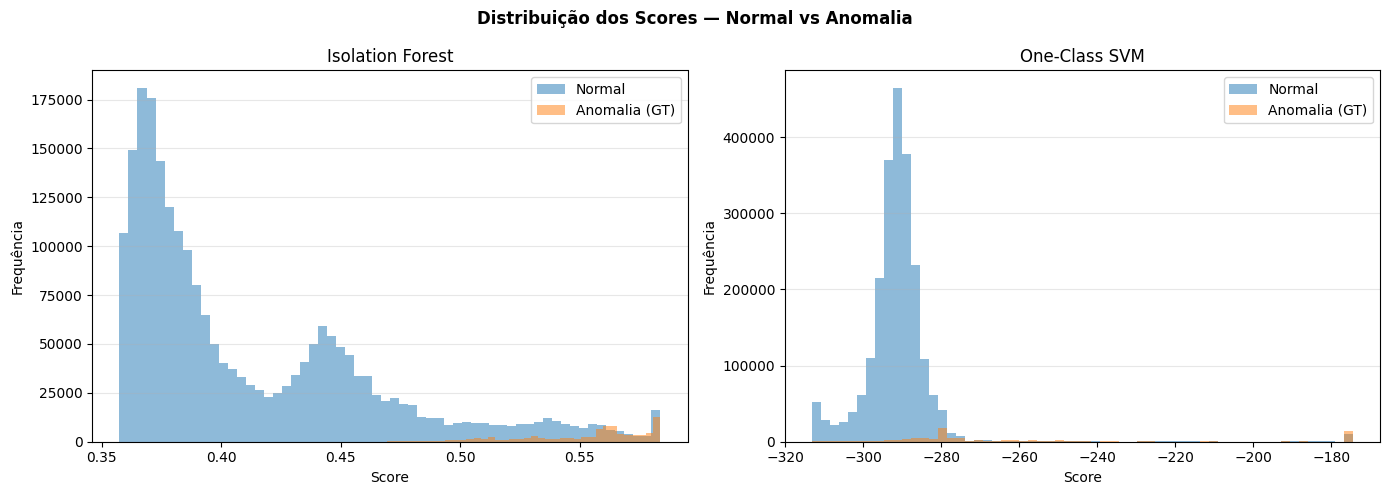


5. DIAGNÓSTICO

uri_attack_pattern
  → Captura intermediária.
    → Verificar distribuição dos scores e efeito do threshold.

suspicious_extension
  → Captura intermediária.
    → Verificar distribuição dos scores e efeito do threshold.

known_scanner_ua
  ✓ Boa separação para os dois modelos.

flood_high_error
  → OCSVM captura muito melhor que o IF.
    → Investigar estrutura das features e sensibilidade do IF.

excessive_encoding
  → Captura intermediária.
    → Verificar distribuição dos scores e efeito do threshold.

Fim do diagnóstico.


In [ ]:
# ============================================================
# 8.7 — Diagnóstico de Desempenho por Tipo de Anomalia
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TIPOS = [
    'uri_attack_pattern',
    'suspicious_extension',
    'known_scanner_ua',
    'flood_high_error',
    'excessive_encoding'
]

# Features comportamentais mais importantes para o diagnóstico
DIAG_FEATURES = [
    'uri_length',
    'uri_depth',
    'uri_param_count',
    'uri_has_susp_ext',
    'uri_has_attack_pattern',
    'uri_encoded_chars',
    'ip_req_count_prev1h',
    'ip_distinct_hosts_prev1h',
    'ip_error_rate_prev1h',
    'ip_post_rate_prev1h',
    'ip_uri_diversity_prev1h',
]

# ============================================================
# 1. Recall por tipo
# ============================================================

print('=' * 75)
print('1. RECALL POR TIPO DE ANOMALIA')
print('=' * 75)

diagnostic_rows = []

for reason in TIPOS:
    mask = gt_mask & (analysis['gt_reason'] == reason)
    total = mask.sum()

    if total == 0:
        continue

    if_detected = (mask & (analysis['pred_if'] == 1)).sum()
    ocsvm_detected = (mask & (analysis['pred_ocsvm'] == 1)).sum()
    neither = (
        mask &
        (analysis['pred_if'] == 0) &
        (analysis['pred_ocsvm'] == 0)
    ).sum()

    diagnostic_rows.append({
        'tipo': reason,
        'total': total,
        'recall_if': if_detected / total,
        'recall_ocsvm': ocsvm_detected / total,
        'nenhum': neither / total
    })

diag_df = pd.DataFrame(diagnostic_rows)

display(
    diag_df.style
    .format({
        'recall_if': '{:.1%}',
        'recall_ocsvm': '{:.1%}',
        'nenhum': '{:.1%}'
    })
)

# ============================================================
# 2. Falsos negativos: o que nenhum modelo conseguiu detectar?
# ============================================================

print('\n' + '=' * 75)
print('2. FALSOS NEGATIVOS — NENHUM MODELO DETECTOU')
print('=' * 75)

fn = analysis[
    gt_mask &
    (analysis['pred_if'] == 0) &
    (analysis['pred_ocsvm'] == 0)
].copy()

print(f'Total: {len(fn):,} de {gt_mask.sum():,} '
      f'({len(fn) / gt_mask.sum():.1%})')
print('\nPor tipo:')

fn_by_type = (
    fn['gt_reason']
    .value_counts()
    .rename('quantidade')
    .to_frame()
)

fn_by_type['percentual'] = fn_by_type['quantidade'] / len(fn)

display(
    fn_by_type.style.format({'percentual': '{:.1%}'})
)

# ============================================================
# 3. Comparação das features:
#    anomalias detectadas vs anomalias perdidas
# ============================================================

print('\n' + '=' * 75)
print('3. FEATURES — DETECTADOS vs PERDIDOS')
print('=' * 75)

for reason in TIPOS:

    attack = analysis[
        gt_mask &
        (analysis['gt_reason'] == reason)
    ]

    if len(attack) == 0:
        continue

    detected = attack[
        (attack['pred_if'] == 1) |
        (attack['pred_ocsvm'] == 1)
    ]

    missed = attack[
        (attack['pred_if'] == 0) &
        (attack['pred_ocsvm'] == 0)
    ]

    if len(missed) == 0:
        continue

    print(f'\n--- {reason} ---')
    print(f'Detectados por algum modelo: {len(detected):,}')
    print(f'Perdidos pelos dois modelos : {len(missed):,}')

    rows = []

    for col in DIAG_FEATURES:
        if col not in analysis.columns:
            continue

        d = detected[col].median()
        m = missed[col].median()

        rows.append({
            'feature': col,
            'mediana_detectados': d,
            'mediana_perdidos': m,
            'diferença_%': (
                ((d - m) / abs(m) * 100)
                if m != 0 else np.nan
            )
        })

    feature_df = pd.DataFrame(rows)

    display(
        feature_df.style.format({
            'mediana_detectados': '{:.3f}',
            'mediana_perdidos': '{:.3f}',
            'diferença_%': '{:+.1f}%'
        })
    )

# ============================================================
# 4. Separação dos scores
# ============================================================

print('\n' + '=' * 75)
print('4. DISTRIBUIÇÃO DOS SCORES — NORMAL vs ANOMALIA')
print('=' * 75)

normal = analysis[~gt_mask]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, score_col, title in [
    (axes[0], 'if_score', 'Isolation Forest'),
    (axes[1], 'ocsvm_score', 'One-Class SVM')
]:

    # Limita aos percentis para evitar que poucos outliers
    # destruam a visualização
    lo = analysis[score_col].quantile(0.01)
    hi = analysis[score_col].quantile(0.99)

    normal_scores = normal[score_col].clip(lo, hi)
    anomaly_scores = analysis.loc[gt_mask, score_col].clip(lo, hi)

    ax.hist(
        normal_scores,
        bins=60,
        alpha=0.5,
        label='Normal'
    )

    ax.hist(
        anomaly_scores,
        bins=60,
        alpha=0.5,
        label='Anomalia (GT)'
    )

    ax.set_title(title)
    ax.set_xlabel('Score')
    ax.set_ylabel('Frequência')
    ax.legend()
    ax.grid(axis='y', alpha=0.3)

plt.suptitle(
    'Distribuição dos Scores — Normal vs Anomalia',
    fontsize=12,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

# ============================================================
# 5. Diagnóstico automático
# ============================================================

print('\n' + '=' * 75)
print('5. DIAGNÓSTICO')
print('=' * 75)

for _, row in diag_df.iterrows():

    reason = row['tipo']
    r_if = row['recall_if']
    r_oc = row['recall_ocsvm']

    print(f'\n{reason}')

    if r_if < 0.20 and r_oc < 0.20:
        print('  ⚠ Baixa captura pelos dois modelos.')
        print('    → Verificar se as features representam esse comportamento.')

    elif r_if < 0.20 and r_oc >= 0.60:
        print('  → OCSVM captura muito melhor que o IF.')
        print('    → Investigar estrutura das features e sensibilidade do IF.')

    elif r_oc < 0.20 and r_if >= 0.60:
        print('  → IF captura muito melhor que o OCSVM.')
        print('    → Investigar estrutura das features e sensibilidade do OCSVM.')

    elif r_if >= 0.60 and r_oc >= 0.60:
        print('  ✓ Boa separação para os dois modelos.')

    else:
        print('  → Captura intermediária.')
        print('    → Verificar distribuição dos scores e efeito do threshold.')

print('\n' + '=' * 75)
print('Fim do diagnóstico.')
print('=' * 75)

In [ ]:
# ============================================================
# EXPLORAÇÃO DOS FALSOS POSITIVOS
# ============================================================

import pandas as pd
import numpy as np

print("=" * 75)
print("EXPLORAÇÃO DOS FALSOS POSITIVOS")
print("=" * 75)


# ------------------------------------------------------------
# 1. IDENTIFICAR FALSOS POSITIVOS
# ------------------------------------------------------------

analysis['fp_if'] = (
    (analysis['pred_if'] == 1) &
    (analysis['gt_anomaly'] == 0)
)

analysis['fp_ocsvm'] = (
    (analysis['pred_ocsvm'] == 1) &
    (analysis['gt_anomaly'] == 0)
)

analysis['fp_ambos'] = (
    analysis['fp_if'] &
    analysis['fp_ocsvm']
)

fp_if = analysis[analysis['fp_if']].copy()
fp_ocsvm = analysis[analysis['fp_ocsvm']].copy()
fp_ambos = analysis[analysis['fp_ambos']].copy()

normal = analysis[analysis['gt_anomaly'] == 0].copy()


print("\n--- RESUMO ---")

print(f"IF:")
print(f"  Falsos positivos : {len(fp_if):,}")
print(f"  Total normal     : {len(normal):,}")
print(f"  Taxa de FP       : {len(fp_if) / len(normal) * 100:.2f}%")

print(f"\nOCSVM:")
print(f"  Falsos positivos : {len(fp_ocsvm):,}")
print(f"  Total normal     : {len(normal):,}")
print(f"  Taxa de FP       : {len(fp_ocsvm) / len(normal) * 100:.2f}%")

print(f"\nDetectados pelos DOIS:")
print(f"  {len(fp_ambos):,}")


# ============================================================
# 2. FUNÇÃO DE EXPLORAÇÃO
# ============================================================

def explorar_fp(df, nome, top_n=20):

    print("\n")
    print("=" * 75)
    print(f"FALSOS POSITIVOS — {nome}")
    print("=" * 75)

    if len(df) == 0:
        print("Nenhum falso positivo.")
        return

    # --------------------------------------------------------
    # URI
    # --------------------------------------------------------

    print("\n--- URIs MAIS FREQUENTES ---")

    uri_counts = (
        df['uri']
        .value_counts()
        .head(top_n)
    )

    print(uri_counts.to_string())


    # --------------------------------------------------------
    # IP
    # --------------------------------------------------------

    print("\n--- IPs MAIS FREQUENTES ---")

    ip_counts = (
        df['ip']
        .value_counts()
        .head(top_n)
    )

    print(ip_counts.to_string())


    # --------------------------------------------------------
    # User-Agent
    # --------------------------------------------------------

    print("\n--- USER-AGENTS MAIS FREQUENTES ---")

    ua_counts = (
        df['user_agent']
        .fillna('(vazio)')
        .value_counts()
        .head(15)
    )

    print(ua_counts.to_string())


    # --------------------------------------------------------
    # STATUS
    # --------------------------------------------------------

    print("\n--- STATUS HTTP ---")

    status_counts = (
        df['status']
        .value_counts()
        .sort_index()
    )

    print(status_counts.to_string())


    # --------------------------------------------------------
    # MÉTODO
    # --------------------------------------------------------

    print("\n--- MÉTODO HTTP ---")

    method_counts = (
        df['http_method']
        .value_counts()
    )

    print(method_counts.to_string())


# ============================================================
# 3. EXPLORAR CADA MODELO
# ============================================================

explorar_fp(fp_if, "ISOLATION FOREST")

explorar_fp(fp_ocsvm, "ONE-CLASS SVM")


# ============================================================
# 4. FALSOS POSITIVOS COMPARTILHADOS
# ============================================================

print("\n")
print("=" * 75)
print("FALSOS POSITIVOS DETECTADOS PELOS DOIS MODELOS")
print("=" * 75)

if len(fp_ambos) > 0:

    print(f"\nTotal: {len(fp_ambos):,}")

    print("\n--- URIs MAIS FREQUENTES ---")
    print(
        fp_ambos['uri']
        .value_counts()
        .head(30)
        .to_string()
    )

    print("\n--- IPs MAIS FREQUENTES ---")
    print(
        fp_ambos['ip']
        .value_counts()
        .head(20)
        .to_string()
    )

    print("\n--- STATUS HTTP ---")
    print(
        fp_ambos['status']
        .value_counts()
        .sort_index()
        .to_string()
    )

    print("\n--- USER-AGENTS ---")
    print(
        fp_ambos['user_agent']
        .fillna('(vazio)')
        .value_counts()
        .head(15)
        .to_string()
    )


# ============================================================
# 5. CARACTERÍSTICAS DOS FALSOS POSITIVOS
# ============================================================

print("\n")
print("=" * 75)
print("CARACTERÍSTICAS — FP vs TRÁFEGO NORMAL")
print("=" * 75)

FP_FEATURES = [
    'uri_length',
    'uri_depth',
    'uri_param_count',
    'uri_encoded_chars',
    'ip_req_count_prev1h',
    'ip_distinct_hosts_prev1h',
    'ip_error_rate_prev1h',
    'ip_post_rate_prev1h',
    'ip_uri_diversity_prev1h',
]

# Garantir que as features estejam disponíveis
fp_analysis = analysis.copy()

for col in FP_FEATURES:
    if col in features_raw.columns:
        fp_analysis[col] = features_raw[col].values

available_features = [
    col for col in FP_FEATURES
    if col in fp_analysis.columns
]

if available_features:

    rows = []

    for feature in available_features:

        rows.append({
            'feature': feature,

            'normal_mediana':
                normal[feature].median()
                if feature in normal.columns
                else fp_analysis.loc[
                    fp_analysis['gt_anomaly'] == 0,
                    feature
                ].median(),

            'IF_FP_mediana':
                fp_analysis.loc[
                    fp_analysis['fp_if'],
                    feature
                ].median(),

            'OCSVM_FP_mediana':
                fp_analysis.loc[
                    fp_analysis['fp_ocsvm'],
                    feature
                ].median(),

            'normal_p95':
                fp_analysis.loc[
                    fp_analysis['gt_anomaly'] == 0,
                    feature
                ].quantile(0.95),

            'IF_FP_p95':
                fp_analysis.loc[
                    fp_analysis['fp_if'],
                    feature
                ].quantile(0.95),

            'OCSVM_FP_p95':
                fp_analysis.loc[
                    fp_analysis['fp_ocsvm'],
                    feature
                ].quantile(0.95),
        })

    fp_features_df = pd.DataFrame(rows)

    display(fp_features_df)

else:
    print("Nenhuma feature encontrada para comparação.")


# ============================================================
# 6. EXEMPLOS CONCRETOS
# ============================================================

print("\n")
print("=" * 75)
print("EXEMPLOS DE FALSOS POSITIVOS")
print("=" * 75)

columns_example = [
    'ip',
    'timestamp',
    'http_method',
    'uri',
    'status',
    'user_agent',
    'if_score',
    'ocsvm_score'
]

columns_example = [
    c for c in columns_example
    if c in analysis.columns
]


print("\n--- IF ---")

display(
    fp_if[
        columns_example
    ]
    .sort_values('if_score')
    .head(30)
)


print("\n--- OCSVM ---")

display(
    fp_ocsvm[
        columns_example
    ]
    .sort_values('ocsvm_score')
    .head(30)
)


print("\n--- AMBOS ---")

display(
    fp_ambos[
        columns_example
    ]
    .head(30)
)

EXPLORAÇÃO DOS FALSOS POSITIVOS


In [ ]:
# ============================================================
# POSSÍVEIS CATEGORIAS NÃO CONTEMPLADAS PELO GT
# ============================================================

fp_both = analysis[
    (analysis['gt_anomaly'] == 0) &
    (analysis['pred_if'] == 1) &
    (analysis['pred_ocsvm'] == 1)
].copy()

print("=" * 75)
print("PADRÕES COMPARTILHADOS PELOS DOIS MODELOS")
print("=" * 75)

print("\n--- URIs ---")
print(fp_both['uri'].value_counts().head(30))

print("\n--- MÉTODOS ---")
print(fp_both['http_method'].value_counts())

print("\n--- STATUS ---")
print(fp_both['status'].value_counts().sort_index())

print("\n--- USER-AGENTS ---")
print(
    fp_both['user_agent']
    .fillna('(vazio)')
    .value_counts()
    .head(30)
)

PADRÕES COMPARTILHADOS PELOS DOIS MODELOS

--- URIs ---
uri
/                                                                                             644
/comunicauem/xmlrpc.php                                                                       578
/comunicauem/wp-comments-post.php                                                             190
/PhoneBackup/2RCf3IIoljUgo3XDpQ0qaGnROmD.php                                                  120
/forgot_password.php                                                                           82
/clusterList                                                                                   79
/session/create                                                                                76
/service.web                                                                                   76
/_users/_all_docs                                                                              73
/wp-content/plugins/seo-local-rank/admin/vendor/datatables

In [ ]:
patterns = {
    'wordpress_xmlrpc': r'/xmlrpc\.php',
    'wordpress_comments': r'/wp-comments-post\.php',
    'wordpress_root': r'^/(wp-login\.php|wp-admin)',
    'scalaj_http': r'scalaj-http',
    'googlebot': r'googlebot',
    'seekportbot': r'seekportbot',
    'facebookexternalhit': r'facebookexternalhit',
}

for nome, pattern in patterns.items():

    mask = (
        (analysis['gt_anomaly'] == 0) &
        (analysis['pred_if'] == 1) &
        (analysis['pred_ocsvm'] == 1) &
        (
            analysis['uri'].str.contains(pattern, case=False, na=False) |
            analysis['user_agent'].str.contains(pattern, case=False, na=False)
        )
    )

    print(f"{nome:25s}: {mask.sum():,}")

wordpress_xmlrpc         : 580
wordpress_comments       : 191
wordpress_root           : 0
scalaj_http              : 129
googlebot                : 32
seekportbot              : 453
facebookexternalhit      : 3
